# Wellbeing Atlas — Country Data Analysis

Explore the relationship between World Happiness Report 2023 scores and selected country indicators from the UN country-profile dataset.

**Workflow:** load and standardize data → identify unmatched country names → merge → inspect data quality → analyze happiness and related indicators.

> Correlations describe associations; they do not establish causation.

## 1. Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

## 2. Load, standardize, and merge datasets

In [2]:
un_df = pd.read_csv("country_profile_variables.csv")
whr_df = pd.read_csv("WHR2023.csv")

un_df = un_df.rename(columns={"country": "Country"})
whr_df = whr_df.rename(columns={
    "Country name": "Country",
    "Ladder score": "Happiness Score"
})

for data in (un_df, whr_df):
    data["Country"] = data["Country"].astype("string").str.strip()

# Identify exact country-name mismatches before merging.
unmatched_un = un_df.loc[
    ~un_df["Country"].isin(whr_df["Country"]), ["Country"]
].assign(Dataset="UN Country Profiles")

unmatched_whr = whr_df.loc[
    ~whr_df["Country"].isin(un_df["Country"]), ["Country"]
].assign(Dataset="World Happiness Report 2023")

unmatched_countries = pd.concat(
    [unmatched_un, unmatched_whr], ignore_index=True
)
unmatched_countries.to_csv("unmatched_countries.csv", index=False)

# Keep only countries represented in both datasets.
df = un_df.merge(whr_df, on="Country", how="inner")

print(f"UN dataset: {un_df.shape[0]} rows")
print(f"WHR dataset: {whr_df.shape[0]} rows")
print(f"Merged dataset: {df.shape[0]} rows, {df['Country'].nunique()} countries")
print(f"Unmatched country records saved: {len(unmatched_countries)}")
display(unmatched_countries.head(10))

UN dataset: 229 rows
WHR dataset: 137 rows
Merged dataset: 119 rows, 119 countries
Unmatched country records saved: 128


,Country,Dataset
0,American Samoa,UN Country Profiles
1,Andorra,UN Country Profiles
2,Angola,UN Country Profiles
3,Anguilla,UN Country Profiles
4,Antigua and Barbuda,UN Country Profiles
5,Aruba,UN Country Profiles
6,Azerbaijan,UN Country Profiles
7,Bahamas,UN Country Profiles
8,Barbados,UN Country Profiles
9,Belarus,UN Country Profiles


## 3. Prepare life expectancy and inspect data quality

In [3]:
life_col = "Life expectancy at birth (females/males, years)"

if life_col in df.columns:
    life_parts = df[life_col].astype("string").str.extract(
        r"([\d.]+)\s*/\s*([\d.]+)"
    )
    df["LifeExp_f"] = pd.to_numeric(life_parts[0], errors="coerce")
    df["LifeExp_m"] = pd.to_numeric(life_parts[1], errors="coerce")
    df["Life expectancy at birth (years)"] = df[
        ["LifeExp_f", "LifeExp_m"]
    ].mean(axis=1)

print("Dataset shape:", df.shape)
print("Duplicate country names:", df["Country"].duplicated().sum())
display(df.head())

missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
missing_summary = pd.DataFrame({
    "Missing Values": missing,
    "Missing (%)": (100 * missing / len(df)).round(2)
})
display(missing_summary)

Dataset shape: (119, 71)
Duplicate country names: 0


,Country,Region,Surface area (km2),Population in thousands (2017),"Population density (per km2, 2017)","Sex ratio (m per 100 f, 2017)",GDP: Gross domestic product (million current US$),"GDP growth rate (annual %, const. 2005 prices)",GDP per capita (current US$),Economy: Agriculture (% of GVA),...,Explained by: Log GDP per capita,Explained by: Social support,Explained by: Healthy life expectancy,Explained by: Freedom to make life choices,Explained by: Generosity,Explained by: Perceptions of corruption,Dystopia + residual,LifeExp_f,LifeExp_m,Life expectancy at birth (years)
0,Afghanistan,SouthernAsia,652864,35530,54.4,106.3,20270,-2.4,623.2,23.3,...,0.645,0.000,0.087,0.000,0.093,0.059,0.976,63.5,61.0,62.25
1,Albania,SouthernEurope,28748,2930,106.9,101.9,11541,2.6,3984.2,22.4,...,1.449,0.951,0.480,0.549,0.133,0.037,1.678,79.9,75.6,77.75
2,Algeria,NorthernAfrica,2381741,41318,17.3,102.0,164779,3.8,4154.1,12.2,...,1.353,1.298,0.409,0.252,0.073,0.152,1.791,76.5,74.1,75.3
3,Argentina,SouthAmerica,2780400,44271,16.2,95.9,632343,2.4,14564.5,6.0,...,1.590,1.388,0.427,0.587,0.088,0.082,1.861,79.8,72.2,76.0
4,Armenia,WesternAsia,29743,2930,102.9,88.8,10529,3.0,3489.1,19.0,...,1.466,1.134,0.443,0.551,0.053,0.160,1.534,77.0,70.6,73.8


,Missing Values,Missing (%)
Healthy life expectancy,1,0.84
Explained by: Healthy life expectancy,1,0.84
Dystopia + residual,1,0.84


## 4. Happiness score: summary and distribution

,Happiness Score
count,119.000000
mean,5.568756
std,1.171323
min,1.859000
25%,4.634500
50%,5.738000
75%,6.420500
max,7.804000


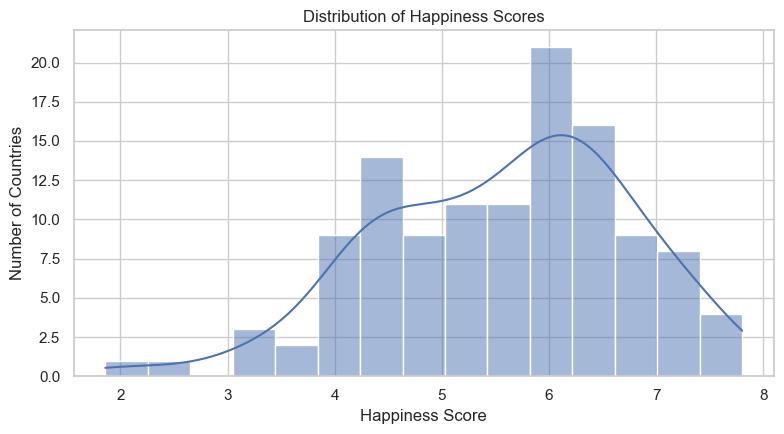

In [4]:
df["Happiness Score"] = pd.to_numeric(df["Happiness Score"], errors="coerce")
display(df["Happiness Score"].describe().to_frame())

scores = df["Happiness Score"].dropna()
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.histplot(scores, bins=15, kde=True, ax=ax)
ax.set(title="Distribution of Happiness Scores", xlabel="Happiness Score",
       ylabel="Number of Countries")
plt.tight_layout()
plt.show()

## 5. Highest and lowest happiness scores

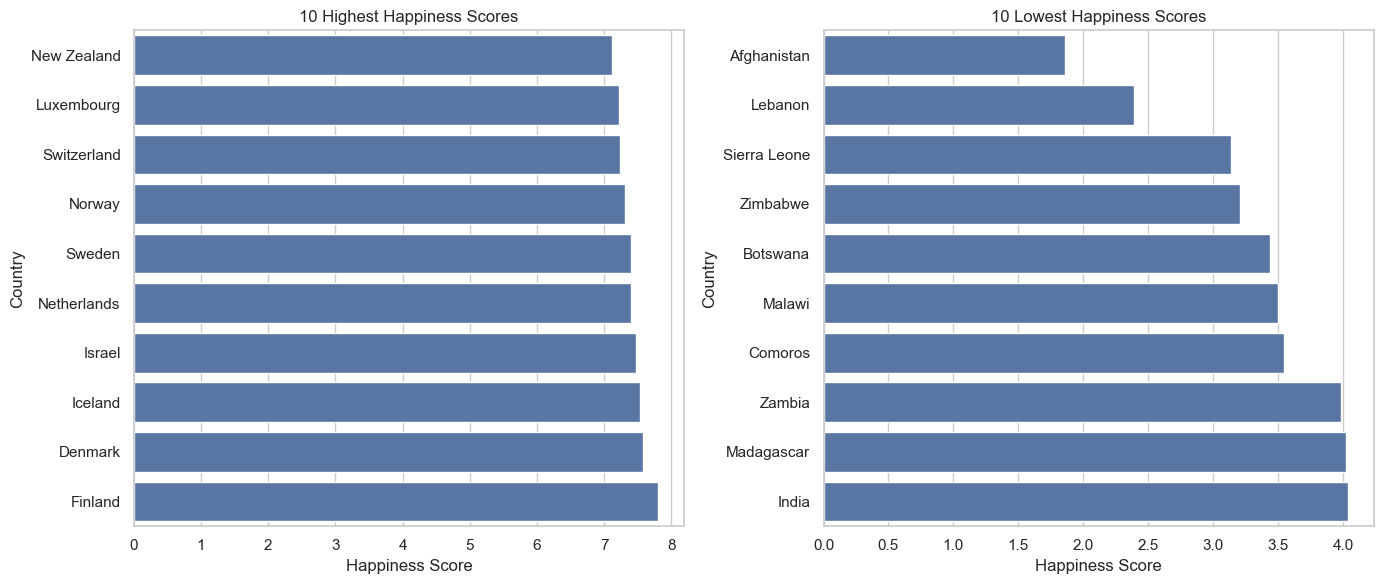

In [5]:
happiness_data = df.dropna(subset=["Country", "Happiness Score"])
top_10 = happiness_data.nlargest(10, "Happiness Score").sort_values("Happiness Score")
bottom_10 = happiness_data.nsmallest(10, "Happiness Score").sort_values("Happiness Score")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.barplot(data=top_10, x="Happiness Score", y="Country", ax=axes[0])
axes[0].set_title("10 Highest Happiness Scores")
sns.barplot(data=bottom_10, x="Happiness Score", y="Country", ax=axes[1])
axes[1].set_title("10 Lowest Happiness Scores")
plt.tight_layout()
plt.show()

## 6. Correlation with selected indicators

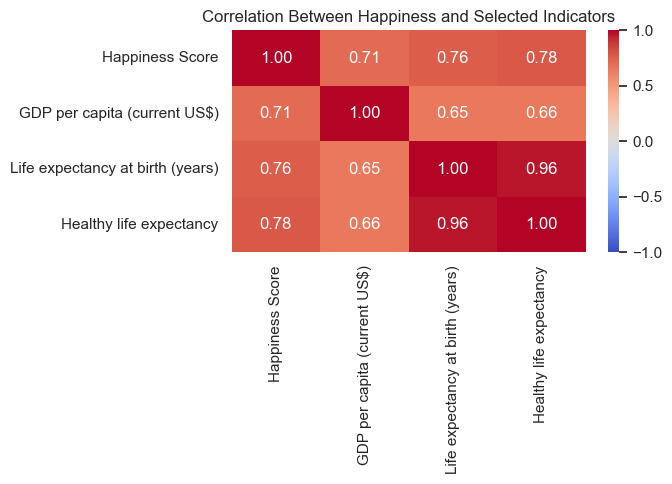

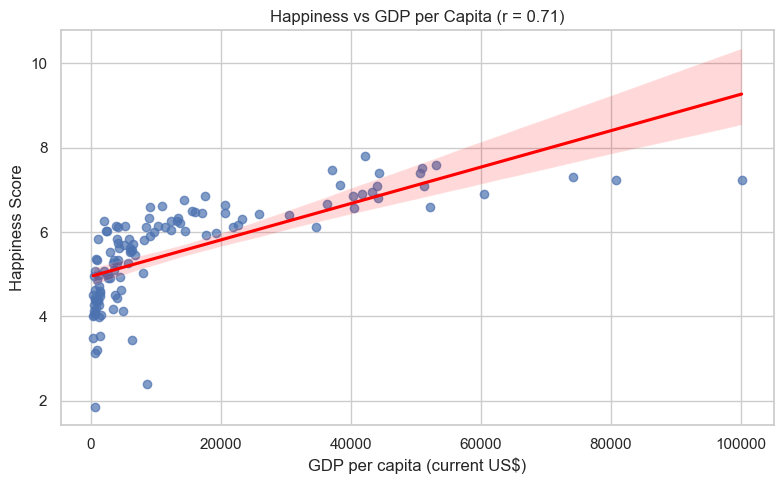

Countries included: 119
Pearson correlation: 0.705


In [6]:
indicators = [
    "Happiness Score",
    "GDP per capita (current US$)",
    "Life expectancy at birth (years)",
    "Healthy life expectancy"
]
available = [col for col in indicators if col in df.columns]

for col in available:
    df[col] = pd.to_numeric(df[col], errors="coerce")

corr = df[available].corr(numeric_only=True)
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1,
            center=0, fmt=".2f")
plt.title("Correlation Between Happiness and Selected Indicators")
plt.tight_layout()
plt.show()

# GDP per capita vs happiness, when both variables are available.
x_col = "GDP per capita (current US$)"
if x_col in df.columns:
    plot_df = df[[x_col, "Happiness Score", "Country"]].dropna(
        subset=[x_col, "Happiness Score"]
    )
    if len(plot_df) >= 2:
        r = plot_df[x_col].corr(plot_df["Happiness Score"])
        plt.figure(figsize=(8, 5))
        sns.regplot(data=plot_df, x=x_col, y="Happiness Score",
                    scatter_kws={"alpha": 0.7},
                    line_kws={"color": "red"})
        plt.title(f"Happiness vs GDP per Capita (r = {r:.2f})")
        plt.tight_layout()
        plt.show()
        print(f"Countries included: {len(plot_df)}")
        print(f"Pearson correlation: {r:.3f}")

## 7. Compare higher- and lower-happiness groups

In [7]:
comparison_cols = [
    col for col in [
        "GDP per capita (current US$)",
        "Life expectancy at birth (years)"
    ]
    if col in df.columns
]

comparison_df = df.dropna(subset=["Happiness Score"]).copy()
for col in comparison_cols:
    comparison_df[col] = pd.to_numeric(comparison_df[col], errors="coerce")

low_cutoff = comparison_df["Happiness Score"].quantile(0.25)
high_cutoff = comparison_df["Happiness Score"].quantile(0.75)

comparison_df["Happiness Group"] = np.select(
    [
        comparison_df["Happiness Score"] <= low_cutoff,
        comparison_df["Happiness Score"] >= high_cutoff
    ],
    ["Lower Happiness (Bottom 25%)", "Higher Happiness (Top 25%)"],
    default="Middle"
)

group_summary = (
    comparison_df.loc[comparison_df["Happiness Group"] != "Middle"]
    .groupby("Happiness Group")[["Happiness Score"] + comparison_cols]
    .mean()
    .round(2)
)
display(group_summary)

,Happiness Score,GDP per capita (current US$),Life expectancy at birth (years)
Happiness Group,,,
Higher Happiness (Top 25%),6.94,39808.89,79.87
Lower Happiness (Bottom 25%),4.00,1863.84,63.67


## Notes

- `unmatched_countries.csv` contains country names found in only one of the two source datasets. Matching is exact after trimming whitespace; alternative spellings are not reconciled automatically.
- The merged dataset uses an inner join, so countries not present in both sources are excluded from the analysis.
- Indicators may refer to different years and may have missing values.